# 01 — EDA (Corevent Analytics)

Overview of loaded tables (Postgres or synthetic fallback). Logic lives in `corevent_analytics`.

In [2]:
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from corevent_analytics.data import load_data, build_category_transactions, build_user_features

sns.set_theme(style="whitegrid")
tables, source = load_data()
print("source:", source)
{name: len(df) for name, df in tables.items()}

source: synthetic


{'users': 3000,
 'events': 200,
 'orders': 4662,
 'order_items': 4662,
 'favorites': 7440,
 'tickets': 7867,
 'event_ratings': 1551,
 'ticket_types': 383}

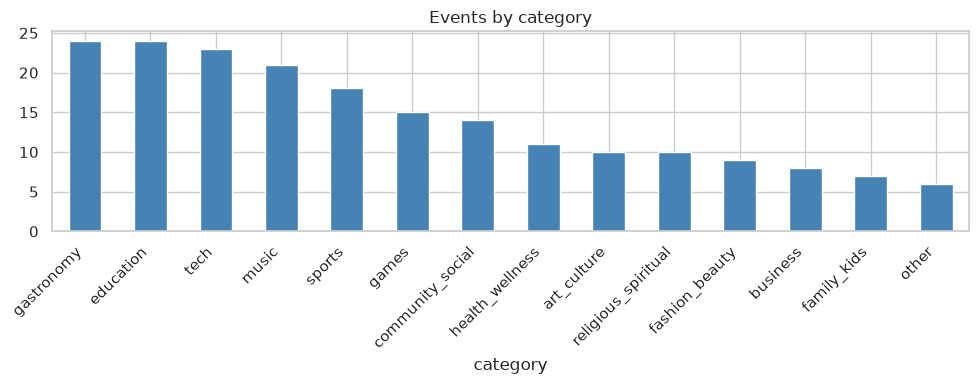

In [3]:
events = tables["events"]
fig, ax = plt.subplots(figsize=(10, 4))
events["category"].value_counts().plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Events by category")
ax.set_xlabel("category")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
plt.show()

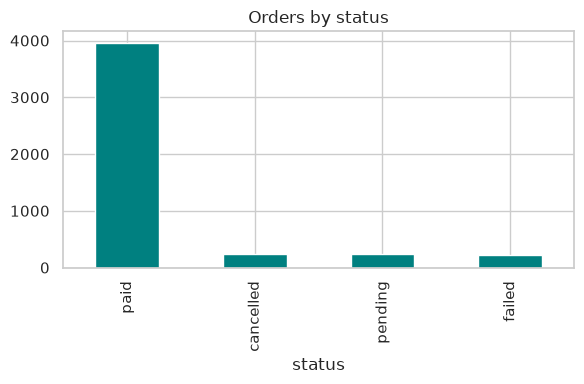

In [4]:
orders = tables["orders"]
if not orders.empty:
    fig, ax = plt.subplots(figsize=(6, 4))
    orders["status"].value_counts().plot(kind="bar", ax=ax, color="teal")
    ax.set_title("Orders by status")
    fig.tight_layout()
    plt.show()
else:
    print("No orders")

In [5]:
transactions = build_category_transactions(tables)
lengths = [len(t) for t in transactions]
print("n_transactions:", len(transactions))
print("avg categories/user:", sum(lengths) / len(lengths) if lengths else 0)

counter = Counter(cat for t in transactions for cat in t)
pd.Series(counter).sort_values(ascending=False).head(14)

n_transactions: 3000
avg categories/user: 2.197


tech                   684
education              679
gastronomy             657
business               657
community_social       641
music                  598
art_culture            595
family_kids            363
sports                 355
health_wellness        350
religious_spiritual    339
games                  323
fashion_beauty         314
other                   36
dtype: int64

In [6]:
features = build_user_features(tables)
features[["age", "n_orders", "n_favorites", "avg_ticket", "checkin_rate"]].describe()

,age,n_orders,n_favorites,avg_ticket,checkin_rate
count,3000.000000,3000.000000,3000.00000,3000.000000,3000.000000
mean,40.919423,1.321333,2.48000,144.096500,0.365744
std,14.245651,1.500054,1.11026,195.222797,0.393173
min,16.859685,0.000000,1.00000,0.000000,0.000000
25%,28.349076,0.000000,1.00000,0.000000,0.000000
50%,40.902122,1.000000,2.00000,40.000000,0.250000
75%,52.934976,2.000000,3.00000,240.000000,0.750000
max,65.853525,5.000000,4.00000,1050.000000,1.000000
